In [ ]:
# Colab 請選 2026.07；安裝到獨立環境，避免更改核心已載入的 NumPy。
from pathlib import Path
import subprocess
import sys
import tempfile

assert sys.version_info[:3] == (3, 12, 13), "請使用書籍或 Colab 2026.07 的 Python 3.12.13"
python = sys.executable
if "google.colab" in sys.modules:
    %pip -q install virtualenv
    env = Path("/content/ch02-book-env")
    if not (env / "bin/python").is_file():
        subprocess.run([python, "-m", "virtualenv", "-q", str(env)], check=True)
    python = str(env / "bin/python")
    pins = ["deepchem==2.8.1.dev20260821122258", "numpy==1.26.4", "scipy==1.17.1",
            "rdkit==2026.9.1", "scikit-learn==1.9.1", "pandas==3.0.6", "matplotlib==3.11.2"]
    subprocess.run([python, "-m", "pip", "install", "-q", *pins], check=True)
    subprocess.run([python, "-m", "pip", "check"], check=True)
work = tempfile.TemporaryDirectory()
script = Path(work.name) / "02-05-conformers.py"
work_dir = Path(work.name)


# 產生與比較三維構形

先執行環境設定，再執行寫入程式與分析結果兩格。修改計算條件後，請重新執行後面兩格。輸出暫存在本次工作資料夾。

<!-- concept-ch00-05:start -->
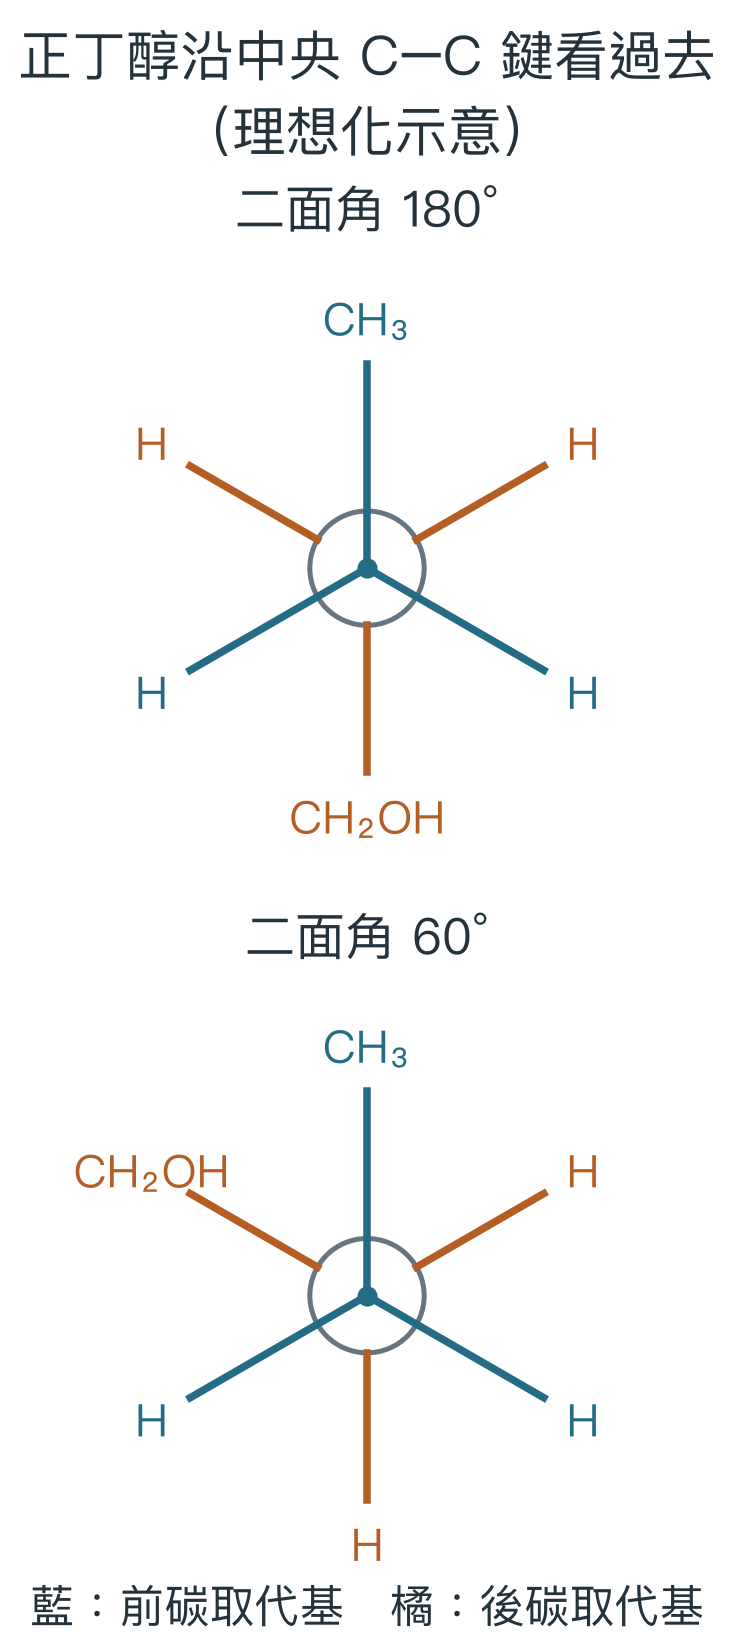

視線沿中央 C–C 鍵，圓心代表前碳，圓圈代表後碳。這四個連續碳可以定義一個**二面角**：前三個碳形成一個平面，後三個碳形成另一個平面，二面角描述兩個平面繞中央 C–C 鍵的相對轉角。上圖兩端基團相對，下圖相隔 60°，連接方式始終相同。這是角度示意，不是下方十二個最佳化構形中的指定結果，也沒有比較能量。

本圖由本書原創繪製，採 [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) 授權。

本節產生十二組起始座標，固定亂數起始設定以便重現；程式中的 `randomSeed` 決定抽樣起點，構形數則由另一個參數指定。
<!-- concept-ch00-05:end -->


In [ ]:
%%writefile "{script}"
from pathlib import Path
import os, json
os.environ["MPLBACKEND"] = "Agg"
import deepchem as dc
from rdkit import Chem
from rdkit.Chem import AllChem, Draw, rdMolTransforms
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
_, parts, _ = dc.molnet.load_delaney(featurizer=dc.feat.RawFeaturizer(smiles=True), splitter='index', transformers=[], reload=False, data_dir=os.environ.get('DEEPCHEM_DATA_DIR'))
rows=[]
for part in parts:
 for smi in part.ids:
  mol=Chem.MolFromSmiles(smi)
  assert mol is not None
  rows.append((len(rows)+1,str(smi),mol))

assert len(rows) == 1128
def lookup(smiles):
 key=Chem.MolToSmiles(Chem.MolFromSmiles(smiles))
 return next(row for row in rows if Chem.MolToSmiles(row[2])==key)
row_id, original, base=lookup('CCCCO')
mol = Chem.AddHs(base)
params = AllChem.ETKDGv3()
params.randomSeed = 42
params.numThreads = 1
ids = list(AllChem.EmbedMultipleConfs(mol, numConfs=12, params=params))
assert ids and AllChem.MMFFHasAllMoleculeParams(mol)
results = AllChem.MMFFOptimizeMoleculeConfs(
    mol, numThreads=1, maxIters=1000, mmffVariant="MMFF94"
)
converged=[(cid,float(energy)) for cid,(status,energy) in zip(ids,results) if status==0]
assert converged
emin=min(e for _,e in converged)
chain=mol.GetSubstructMatch(Chem.MolFromSmarts('[CH3]-[CH2]-[CH2]-[CH2]-[OH]'))
angles=[rdMolTransforms.GetDihedralDeg(mol.GetConformer(cid),*chain[:4]) for cid,_ in converged]
energies=[e-emin for _,e in converged]
print('Butan-1-ol ESOL row',row_id,'requested=12 embedded=',len(ids),'converged=',len(converged))
print('relative energies kcal/mol', [round(x,4) for x in energies])

records = []
for cid, (status, energy) in zip(ids, results):
    angle = rdMolTransforms.GetDihedralDeg(mol.GetConformer(cid), *chain[:4])
    is_converged = status == 0
    relative = float(energy) - emin if is_converged else None
    records.append({"conformer_id": cid, "converged": is_converged,
                    "energy_kcal_mol": float(energy),
                    "relative_energy_kcal_mol": relative, "dihedral_deg": angle})
conformer_table = pd.DataFrame(records)
conformer_table.to_csv("conformers.csv", index=False)
Path("results.json").write_text(json.dumps({"dataset_rows": len(rows), "source_row": row_id,
    "requested": 12, "embedded": len(ids), "converged": len(converged),
    "relative_energies_kcal_mol": energies, "dihedrals_deg": angles}, indent=2))
out = Path('figures')
out.mkdir(exist_ok=True)
fig=plt.figure(figsize=(11,4.6))
ax=fig.add_subplot(121,projection='3d')
best=min(converged,key=lambda pair:pair[1])[0];conf=mol.GetConformer(best)
for bond in base.GetBonds():
 a,b=(conf.GetAtomPosition(i) for i in (bond.GetBeginAtomIdx(),bond.GetEndAtomIdx()))
 ax.plot([a.x,b.x],[a.y,b.y],[a.z,b.z],color='#64748b',lw=3)
for atom in base.GetAtoms():
 p=conf.GetAtomPosition(atom.GetIdx());ax.scatter(p.x,p.y,p.z,color=('#dc2626' if atom.GetSymbol()=='O' else '#334155'),s=75)
 ax.text(p.x,p.y,p.z,atom.GetSymbol())
ax.set(xlabel='x (Å)',ylabel='y (Å)',zlabel='z (Å)',title='Butan-1-ol: one generated conformer')
coords=conf.GetPositions()[:base.GetNumAtoms()]
center=(coords.max(axis=0)+coords.min(axis=0))/2
radius=float((coords.max(axis=0)-coords.min(axis=0)).max())/2+0.3
ax.set_xlim(center[0]-radius,center[0]+radius)
ax.set_ylim(center[1]-radius,center[1]+radius)
ax.set_zlim(center[2]-radius,center[2]+radius)
ax.set_box_aspect((1,1,1))
ax2=fig.add_subplot(122)
ax2.scatter(angles,energies,color='#0f766e',s=50)
ax2.set(xlabel='C–C–C–C dihedral (degrees)',ylabel='Relative MMFF94 energy (kcal/mol)',title='12 generated starting conformers')
ax2.grid(alpha=.2);fig.tight_layout();fig.savefig(out/'02-05-conformers.png',dpi=160);plt.close(fig)


In [ ]:
from IPython.display import Image, display
import pandas as pd

run = subprocess.run([python, str(script)], cwd=work_dir, capture_output=True, text=True)
if run.returncode:
    print(run.stderr)
    run.check_returncode()
print(run.stdout.replace("This module requires PyTorch to be installed.\n", "").strip())
conformer_table = pd.read_csv(work_dir / "conformers.csv")
display(conformer_table)
display(Image(filename=str(work_dir / "figures" / "02-05-conformers.png")))
